# 01 — The classic scenario: pretrain, then reuse for a different task

**Question.** You have a network trained on one task. A new task arrives
with limited labels. Is it better to (a) train from scratch, (b) keep the
pretrained features frozen and train only a linear classifier on top
(*linear probe*), or (c) copy the pretrained weights and *fine-tune*?

**What the literature says.**
- Reused features beat random initialization, and the benefit is largest
  when target data is scarce (Yosinski et al. 2014; Donahue et al.,
  *DeCAF*, ICML 2014).
- With enough target data, training from scratch catches up — pretraining
  mostly buys *sample efficiency*, not a better final optimum (He, Girshick
  & Dollár, *Rethinking ImageNet Pre-training*, ICCV 2019).
- Fine-tuning beats frozen features when source and target differ, because
  the representation can adapt (Kornblith et al. 2019).
- **All of this presumes the tasks are related.** How related, matters
  enormously — we check that too, and notebook 03 maps it systematically.

**Setup.** The *related* source-target pair keeps the domain identical but
the classes disjoint — exactly Yosinski et al.'s protocol: pretrain on
digits 5–9, transfer to digits 0–4. The *distant* source is Fashion-MNIST
(clothing photos vs pen strokes). Fine-tuning uses the standard recipe of
discriminative learning rates: the fresh head trains at 1e-3 while the
pretrained encoder moves gently at 1e-4.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

import tllab
from tllab import analysis, data, models, train

tllab.setup()

RELATED_SRC, DISTANT_SRC, TARGET_KEY = "mnist:5-9", "fashion", "mnist:0-4"
related = train.train_or_load_source(RELATED_SRC)
distant = train.train_or_load_source(DISTANT_SRC)
target = data.get_task(TARGET_KEY)
pool = data.subset(target, tllab.q(6000, 1200), seed=99)  # probe pool

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab
[ckpt cached] mnist:5-9: test_acc=0.988


[ckpt cached] fashion: test_acc=0.864


## The experiment

Three conditions on the related pair at each target-data size
n ∈ {10, 25, 100, 1000, 10000} (3 seeds where n ≤ 1000):

| condition | encoder init | encoder trained? | head | LR |
|---|---|---|---|---|
| scratch | random | yes | random | 1e-3 |
| linear probe | pretrained (frozen) | no | trained on embeddings | 1e-2 |
| fine-tune | pretrained | yes (gently) | random | encoder 1e-4, head 1e-3 |

n=10 means **two examples per class** — the few-shot end of the spectrum,
where the pretrained representation has to do almost all the work. A note
on fairness: with a convolutional architecture this small, from-scratch
MNIST training is a strong baseline even at tiny n (the inductive bias does
a lot), so every condition gets a generous, fully converged budget — the
gaps below are not artifacts of under-training the baseline.

In [2]:
EPOCHS = {10: 60, 25: 60, 100: 40, 1000: 15, 10000: 8}
BATCH = {10: 8, 25: 16, 100: 32, 1000: 128, 10000: 128}
EVERY = {10: 10, 25: 10, 100: 10, 1000: 1, 10000: 1}


def related_transfer() -> pd.DataFrame:
    rows = []
    for n, epochs in EPOCHS.items():
        n_run = tllab.q(n, max(n // 10, 10))
        epochs = tllab.q(epochs, 2)
        for seed in (tllab.seeds() if n <= 1000 else [0]):
            sub = data.subset(target, n_run, seed)

            m = models.new_cnn(target.n_classes, seed)
            scratch = train.fit(m, sub, epochs=epochs, batch_size=BATCH[n],
                                seed=seed, eval_every=EVERY[n]).final_acc

            probe = train.linear_probe(related, pool, n_train=n_run,
                                       seed=seed, cache_key="01-" + RELATED_SRC)

            m = models.transfer_first_k(related, k=5,
                                        n_classes=target.n_classes, seed=seed)
            finetune = train.fit(m, sub, epochs=epochs, lr=1e-4, head_lr=1e-3,
                                 batch_size=BATCH[n], seed=seed,
                                 eval_every=EVERY[n]).final_acc

            for cond, acc in [("scratch", scratch), ("linear probe", probe),
                              ("fine-tune", finetune)]:
                rows.append({"condition": cond, "n_train": n_run,
                             "seed": seed, "acc": acc})
            print(f"  n={n_run} seed={seed}: scratch={scratch:.3f} "
                  f"probe={probe:.3f} finetune={finetune:.3f}")
    return pd.DataFrame(rows)


df = train.cached_sweep("01_related_transfer", related_transfer)
df.pivot_table(index="n_train", columns="condition", values="acc")

[sweep cached] 01_related_transfer.csv


condition,fine-tune,linear probe,scratch
n_train,,,
10,0.837647,0.831550,0.702342
25,0.922618,0.892975,0.801258
100,0.952131,0.932866,0.943893
1000,0.976390,0.974703,0.978400
10000,0.992800,0.982681,0.994746


figure -> artifacts/figures/01_transfer_vs_n.png


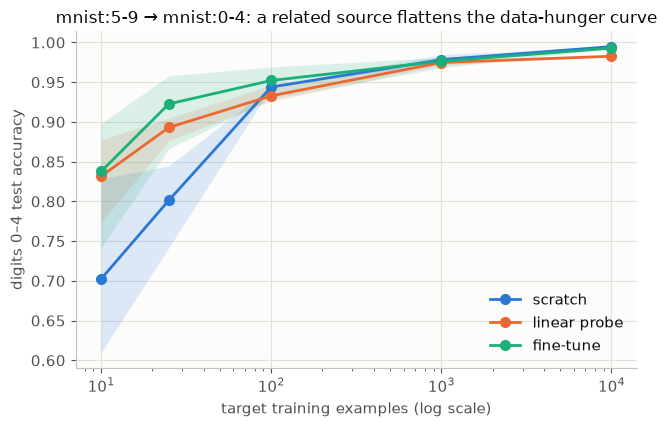

In [3]:
plt.figure(figsize=(6.6, 4.4))
analysis.plot_curves(df, x="n_train", y="acc", hue="condition", logx=True,
                     ylabel="digits 0–4 test accuracy",
                     title=f"{RELATED_SRC} → {TARGET_KEY}: a related source "
                           "flattens the data-hunger curve")
plt.gca().set_xlabel("target training examples (log scale)")
analysis.savefig("01_transfer_vs_n")

## Does *any* pretraining help this much? Swap in a distant source

Same protocol, but the encoder now comes from Fashion-MNIST — photographs
of clothing, nothing like pen strokes. If transfer were a property of
"having been trained on something", the curves would match the related
source. They don't.

In [4]:
def distant_transfer() -> pd.DataFrame:
    rows = []
    for n, epochs in EPOCHS.items():
        n_run = tllab.q(n, max(n // 10, 10))
        epochs = tllab.q(epochs, 2)
        for seed in (tllab.seeds() if n <= 1000 else [0]):
            sub = data.subset(target, n_run, seed)
            probe = train.linear_probe(distant, pool, n_train=n_run,
                                       seed=seed, cache_key="01-" + DISTANT_SRC)
            m = models.transfer_first_k(distant, k=5,
                                        n_classes=target.n_classes, seed=seed)
            finetune = train.fit(m, sub, epochs=epochs, lr=1e-4, head_lr=1e-3,
                                 batch_size=BATCH[n], seed=seed,
                                 eval_every=EVERY[n]).final_acc
            rows.append({"condition": "probe (distant)", "n_train": n_run,
                         "seed": seed, "acc": probe})
            rows.append({"condition": "fine-tune (distant)", "n_train": n_run,
                         "seed": seed, "acc": finetune})
            print(f"  n={n_run} seed={seed}: probe={probe:.3f} "
                  f"finetune={finetune:.3f}")
    return pd.DataFrame(rows)


df_far = train.cached_sweep("01_distant_transfer", distant_transfer)

[sweep cached] 01_distant_transfer.csv


figure -> artifacts/figures/01_related_vs_distant.png


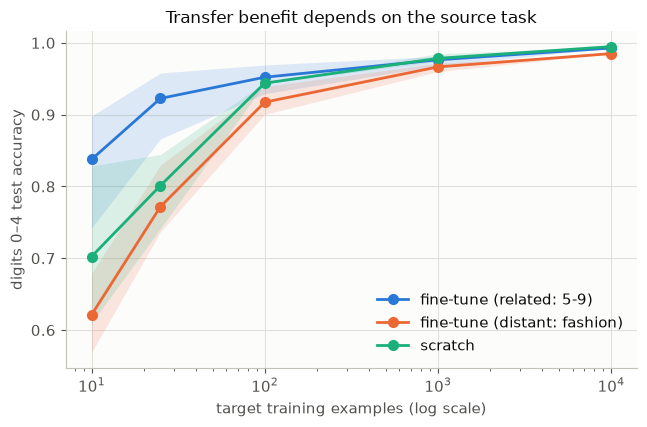

In [5]:
scratch_df = df[df.condition == "scratch"]
comp = pd.concat([
    df[df.condition == "fine-tune"].assign(condition="fine-tune (related: 5-9)"),
    df_far[df_far.condition == "fine-tune (distant)"]
        .assign(condition="fine-tune (distant: fashion)"),
    scratch_df,
])
plt.figure(figsize=(6.6, 4.4))
analysis.plot_curves(comp, x="n_train", y="acc", hue="condition", logx=True,
                     ylabel="digits 0–4 test accuracy",
                     title="Transfer benefit depends on the source task")
plt.gca().set_xlabel("target training examples (log scale)")
analysis.savefig("01_related_vs_distant")

## Takeaways

- **Extreme scarcity: a related source wins big.** At n=10–25 the
  pretrained encoder already knows digit strokes, so a couple of examples
  per class suffice to re-aim it; scratch is 8–13 points behind.
- **The advantage shrinks fast as data grows** — on this easy target the
  gap is mostly gone by n≈100 and fully gone at n=10k. That is He et al.'s
  (2019) ImageNet-scale finding in miniature: pretraining buys sample
  efficiency, not a better final optimum, and *the easier the target task,
  the narrower the data window where it pays*. (A small CNN's inductive
  bias makes tiny-data MNIST much less hopeless than tiny-data natural
  images, which is why the window here is narrower than in DeCAF-era
  benchmarks.)
- **The frozen probe is competitive early, capped late** — with plenty of
  target data, not being allowed to adapt becomes the bottleneck
  (notebook 04 turns this into outright negative transfer).
- **A distant source is a different story.** Fashion features barely help
  digits — at the few-shot end they trail the related source badly.
  "Pretrained" is not a magic word; *what* the network was pretrained on
  decides everything. Notebook 03 measures this systematically, and
  notebook 04 shows the pathological extreme.

**References.** Donahue et al., *DeCAF* (ICML 2014); Yosinski et al.
(NeurIPS 2014); Kornblith, Shlens & Le (CVPR 2019); He, Girshick & Dollár
(ICCV 2019).

In [6]:
if not tllab.config.QUICK:
    g = df.groupby(["condition", "n_train"])["acc"].mean()
    gf = df_far.groupby(["condition", "n_train"])["acc"].mean()
    ft10, sc10 = g["fine-tune"][10], g["scratch"][10]
    ft25, sc25 = g["fine-tune"][25], g["scratch"][25]
    ft10k, sc10k = g["fine-tune"][10000], g["scratch"][10000]
    pr10k = g["linear probe"][10000]
    far25 = gf["fine-tune (distant)"][25]
    analysis.claim("related fine-tune beats scratch at n=10 by >5 pts",
                   ft10 - sc10 > 0.05, f"{ft10:.3f} vs {sc10:.3f}", hard=True)
    analysis.claim("related fine-tune beats scratch at n=25 by >3 pts",
                   ft25 - sc25 > 0.03, f"{ft25:.3f} vs {sc25:.3f}", hard=True)
    analysis.claim("gap nearly closed at n=10k (<2 pts)",
                   abs(ft10k - sc10k) < 0.02, f"{ft10k:.3f} vs {sc10k:.3f}")
    analysis.claim("fine-tune beats frozen probe at n=10k",
                   ft10k > pr10k, f"{ft10k:.3f} vs {pr10k:.3f}")
    analysis.claim("distant source trails related source at n=25 by >3 pts",
                   ft25 - far25 > 0.03, f"{ft25:.3f} vs {far25:.3f}")

CLAIM CHECK [PASS] related fine-tune beats scratch at n=10 by >5 pts — 0.838 vs 0.702
CLAIM CHECK [PASS] related fine-tune beats scratch at n=25 by >3 pts — 0.923 vs 0.801
CLAIM CHECK [PASS] gap nearly closed at n=10k (<2 pts) — 0.993 vs 0.995
CLAIM CHECK [PASS] fine-tune beats frozen probe at n=10k — 0.993 vs 0.983
CLAIM CHECK [PASS] distant source trails related source at n=25 by >3 pts — 0.923 vs 0.772
